# Exploración de Datos Abiertos de MiBici (Octubre 2022 – Septiembre 2026)
**Equipo 35 — TC5061 Operaciones de Aprendizaje Automático**

Este notebook realiza la inspección exploratoria del archivo consolidado `datos_mibici.parquet` (generado por `mibici/dataset.py`) y del catálogo de estaciones `nomenclatura_2026_09.csv`, verificando la calidad de los datos, la distribución temporal y la ausencia de fuga de información.

In [1]:
# 1. Importamos librerías estándar y la configuración centralizada del proyecto
import json
import pandas as pd
import matplotlib.pyplot as plt
from mibici import config, features

# 2. Leemos el manifiesto de versión generado durante la ingesta
with open(config.DATA_VERSION_FILE, "r", encoding="utf-8") as f:
    version_info = json.load(f)

print("Versión SHA-256 corta:", version_info["data_version_short"])
print("Periodo procesado:", version_info["date_range"])
print(f"Filas crudas leídas: {version_info['rows_read_raw']:,}")
print(f"Filas limpias en Parquet: {version_info['rows_written_clean']:,}")

Versión SHA-256 corta: 128979137b46
Periodo procesado: 2022-10_a_2026-09
Filas crudas leídas: 17,927,033
Filas limpias en Parquet: 17,036,839


In [2]:
# 3. Inspeccionamos el catálogo de estaciones (nomenclatura_2026_09.csv)
df_estaciones = features.cargar_nomenclatura()
print(f"Total de estaciones en catálogo: {len(df_estaciones)}")
display(df_estaciones.head())
display(df_estaciones[["latitude", "longitude", "dpcapacity"]].describe())

Total de estaciones en catálogo: 484


,Estacion_Id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


,latitude,longitude,dpcapacity
count,484.000000,484.000000,484.000000
mean,20.678520,-103.361871,16.882231
std,0.022032,0.031626,4.126942
min,20.636130,-103.433215,0.000000
25%,20.665077,-103.384164,15.000000
50%,20.674390,-103.362443,15.000000
75%,20.688609,-103.339320,19.000000
max,20.739523,-103.297112,39.000000


<class 'pandas.DataFrame'>
RangeIndex: 17036839 entries, 0 to 17036838
Data columns (total 8 columns):
 #   Column             Dtype         
---  ------             -----         
 0   Viaje_Id           Int64         
 1   Usuario_Id         Int64         
 2   Genero             string        
 3   Año_de_nacimiento  Int64         
 4   Inicio_del_viaje   datetime64[us]
 5   Fin_del_viaje      datetime64[us]
 6   Origen_Id          Int64         
 7   Destino_Id         Int64         
dtypes: Int64(5), datetime64[us](2), string(1)
memory usage: 1.1 GB
None


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,25437499,173036,M,1991,2022-10-01 00:01:11,2022-10-01 00:08:58,171,158
1,25437502,646533,M,1992,2022-10-01 00:01:41,2022-10-01 00:28:28,312,278
2,25437511,146553,M,1996,2022-10-01 00:03:36,2022-10-01 00:12:30,87,194
3,25437512,1652274,M,1995,2022-10-01 00:03:49,2022-10-01 00:15:51,14,14
4,25437513,535634,M,1994,2022-10-01 00:04:30,2022-10-01 00:08:08,21,21


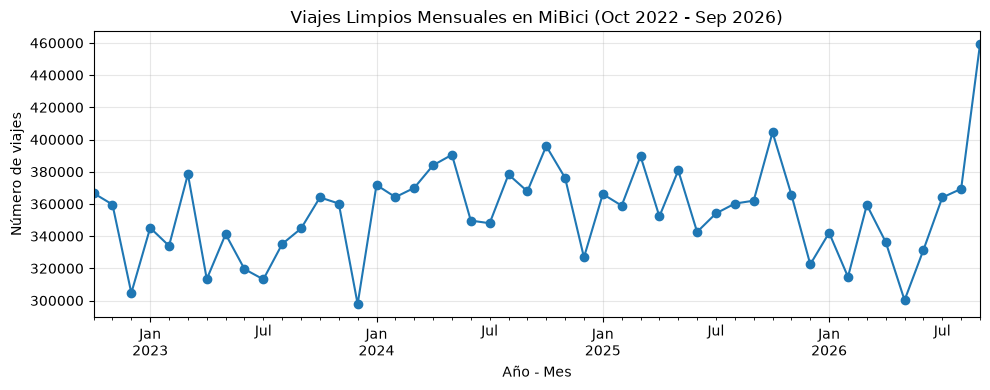

In [3]:
# 4. Cargamos una muestra de viajes limpios del Parquet y verificamos tipos de datos
df_viajes = pd.read_parquet(config.PARQUET_FILE)
print(df_viajes.info())
display(df_viajes.head())

# 5. Graficamos la evolución mensual de viajes limpios (Octubre 2022 - Septiembre 2026)
viajes_por_mes = (
    df_viajes.assign(anio_mes=df_viajes["Inicio_del_viaje"].dt.to_period("M"))
    .groupby("anio_mes")
    .size()
)
viajes_por_mes.plot(kind="line", figsize=(10, 4), marker="o", title="Viajes Limpios Mensuales en MiBici (Oct 2022 - Sep 2026)")
plt.xlabel("Año - Mes")
plt.ylabel("Número de viajes")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()